<br />
<div style="text-align: center;">
<font size="5">数式処理：縦残差と直交距離の関係</font>
</div>
<br />
<div style="text-align: right;">
<font size="4">file: eq_manip_line_errors_build_ans.ipynb</font>
</div>

完成コードと解答文を消し，模式図，共通設定，穴埋めコードを残します．
```bash
pick_works_from_ans gw5_line_errors_build_ans.ipynb -1 '' '4 5 11 13 16 19 22 25 28 31 37'
```

生成物：`gw5_line_errors_build.ipynb`


# はじめに

先週の課題でQR分解とSVDを使って，$y$方向に測る**縦残差**と，直線に垂直な方向に測る**直交距離**を求めました．同じ点と同じ直線については，二つの量を簡単な式で換算できます．

まず，一つの点と一本の直線を図に描き，二つの距離の違いを確認します．次に，直線上の点までの距離をSymPyで最小化し，
$$
\text{直交距離平方和}
=
\frac{\text{縦残差平方和}}{1+m^2}
$$
となる理由を一般的に導きます．ここで$m$は直線の傾きです．

## 到達目標

1. 一点の模式図から，縦残差と直交距離の違いを説明する．
2. SymPyで直線上の最近点を求め，直交距離を計算する．
3. 一点での計算を一般化し，二つの誤差の関係を導く．
4. NumPyで全データ点の誤差を確認する．
5. QR回帰とPCAで最小化する誤差が異なる理由を説明する．

# 1　一点での計算例

点$P=(3,7)$と，
QR回帰で得られた直線$y=\frac54x$を考えます．

- $Q_v$ : 同じ$x=3$を持つ直線上へ垂直(vertical)に下ろした点，
- $Q_\perp$ : 点$P$に最も近い直線上へ直角(perpendicular)に下ろした点(Q perpって読みます)
  
をとします．

- 縦残差(residual)の絶対値$|r|$ : 線分$PQ_v$の長さ，$y$方向に測った,
- 直交距離$d$ : 線分$PQ_\perp$の長さ，直線に垂直な方向に測った
  
です．

直線上の点を$Q(t)=(t,5t/4)$と置き，距離平方
$$
D^2(t)=(t-3)^2+\left(\frac54t-7\right)^2
$$
を$t$について最小化して，$Q_\perp$と$d$を求めなさい．


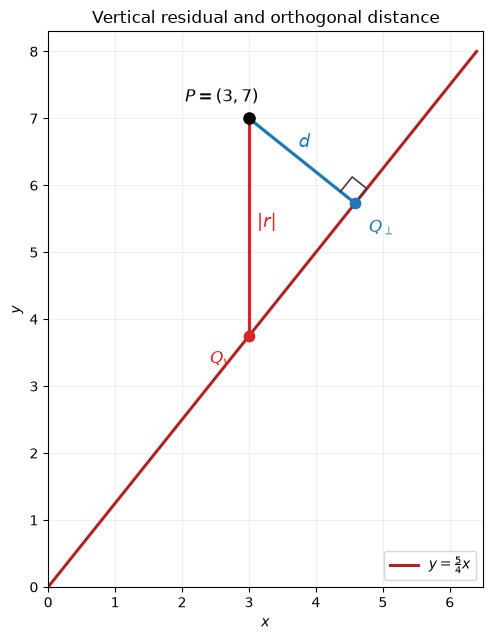

In [1]:
import numpy as np
import matplotlib.pyplot as plt

m_plot = 5/4
p = np.array([3.0, 7.0])
q_vertical = np.array([p[0], m_plot*p[0]])
q_perp = np.array([188/41, 235/41])

x_line = np.linspace(0, 6.4, 300)
fig, ax = plt.subplots(figsize=(7, 6.5))
ax.plot(x_line, m_plot*x_line, color='firebrick', lw=2.2,
        label=r'$y=\frac{5}{4}x$')
ax.scatter(*p, color='black', s=65, zorder=4)
ax.scatter(*q_vertical, color='tab:red', s=55, zorder=4)
ax.scatter(*q_perp, color='tab:blue', s=55, zorder=4)

# 縦残差と直交距離を表す線分です．
ax.plot([p[0], q_vertical[0]], [p[1], q_vertical[1]],
        color='tab:red', lw=2.3)
ax.plot([p[0], q_perp[0]], [p[1], q_perp[1]],
        color='tab:blue', lw=2.3)

# Q_perpで直線と線分PQ_perpが直交することを示します．
u = np.array([1.0, m_plot])
u /= np.linalg.norm(u)
n = np.array([-m_plot, 1.0])
n /= np.linalg.norm(n)
size = 0.28
corner = np.vstack([
    q_perp,
    q_perp + size*u,
    q_perp + size*u + size*n,
    q_perp + size*n,
])
ax.plot(corner[:, 0], corner[:, 1], color='0.25', lw=1.2)

ax.annotate(r'$P=(3,7)$', p, xytext=(-46, 12),
            textcoords='offset points', fontsize=12)
ax.annotate(r'$Q_v$', q_vertical, xytext=(-28, -20),
            textcoords='offset points', color='tab:red', fontsize=12)
ax.annotate(r'$Q_\perp$', q_perp, xytext=(10, -21),
            textcoords='offset points', color='tab:blue', fontsize=12)
ax.text(3.12, (p[1]+q_vertical[1])/2, r'$|r|$',
        color='tab:red', fontsize=13)
ax.text((p[0]+q_perp[0])/2-0.05,
        (p[1]+q_perp[1])/2+0.20, r'$d$',
        color='tab:blue', fontsize=13)

ax.set(xlim=(0, 6.5), ylim=(0, 8.3), xlabel='$x$', ylabel='$y$',
       title='Vertical residual and orthogonal distance')
ax.set_aspect('equal', adjustable='box')
ax.grid(alpha=.2)
ax.legend(loc='lower right')
fig.tight_layout()

fig.savefig(
    "line_errors_one_point.pdf",
    bbox_inches="tight"
)

plt.show()

In [2]:
# 課題用穴埋めコード：空欄を補ってください．
import sympy as sp
from IPython.display import Markdown, display

m = sp.Rational(5, 4)
b = sp.Integer(0)
x_i = sp.Integer(3)
y_i = sp.Integer(7)
t = sp.symbols('t', real=True)

# distance_squared = (             )**2 + (             )**2
# t_perp = sp.solve(sp.Eq(sp.diff(             , t), 0), t)[0]
# x_perp =
# y_perp =

# vertical_residual =
# orthogonal_distance = sp.sqrt(
#     sp.simplify(             .subs(t, t_perp))
# )

# display(sp.Tuple(x_perp, y_perp))
# display(vertical_residual)
# display(sp.simplify(orthogonal_distance))

In [3]:
import sympy as sp
from IPython.display import Markdown, display

m = sp.Rational(5, 4)
b = sp.Integer(0)
x_i = sp.Integer(3)
y_i = sp.Integer(7)
t = sp.symbols('t', real=True)

# 直線上の点Q(t)までの距離平方を最小化します．
distance_squared = (t - x_i)**2 + (m*t + b - y_i)**2
t_perp = sp.solve(sp.Eq(sp.diff(distance_squared, t), 0), t)[0]
x_perp = t_perp
y_perp = m*t_perp + b

vertical_residual = y_i - (m*x_i + b)
orthogonal_distance = sp.sqrt(
    sp.simplify(distance_squared.subs(t, t_perp))
)

display(Markdown(r'直交射影点$Q_\perp$：'))
display(sp.Tuple(x_perp, y_perp))
display(Markdown(r'縦残差$r$：'))
display(vertical_residual)
display(Markdown(r'直交距離$d$：'))
display(sp.simplify(orthogonal_distance))

直交射影点$Q_\perp$：

(188/41, 235/41)

縦残差$r$：

13/4

直交距離$d$：

13*sqrt(41)/41

## 1-1　模式図から分かること

赤い線分$PQ_v$は$x$軸に垂直(vertical)ですが，青い線分$PQ_\perp$は回帰直線と垂直(perpendicular)です．この例では，
$Q_v$(vertical), $Q_\perp$(perpendicular)は
$$
Q_v=\left(3,\frac{15}{4}\right)，\qquad
Q_\perp=\left(\frac{188}{41},\frac{235}{41}\right)
$$
となり，SymPyの計算から
$$
r=\frac{13}{4}，\qquad d=\frac{13}{\sqrt{41}}
$$
が得られます．$d<|r|$であることは，青い線分が点$P$と直線を結ぶ最短の線分であることに対応します．

疑問：なぜ$\sum d_i$は$\sum r_i$よりも小さくなることがあるのか．．．

# 2　直交距離の一般的な導出

点$P_i=(x_i,y_i)$と直線
$$
\ell:y=mx+b
$$
を考える．直線$\ell$上の点を$Q(t)=(t,mt+b)$とすると，$P_i$と$Q(t)$の距離の二乗は
$$
D_i^2(t)=(t-x_i)^2+(mt+b-y_i)^2
$$
である．

$D_i^2(t)$を$t$で微分して整理すると，
$$
\frac{d}{dt}D_i^2(t)
=2(\fbox{ア}+m^2)t
-2\{x_i+m(y_i-\fbox{イ})\}
$$
となる．これが0となる$t$を$t_\perp$とすると，
$$
t_\perp
=\frac{x_i+m(y_i-b)}{m^2+\fbox{ウ}}
$$
である．したがって，$P_i$から直線$\ell$までの直交距離を$d_i$とすると，
$$
d_i^2
=D_i^2(t_\perp)
=\frac{\{y_i-(mx_i+b)\}^2}{m^2+\fbox{エ}}
$$
となる．

ここで，縦残差を
$$
r_i=y_i-(mx_i+b)
$$
と置く．$d_i\geq0$であることに注意すると，
$$
d_i=\frac{|\fbox{オ}|}{\sqrt{1+\fbox{カ}}}
$$
である．空欄ア〜カを埋めよ．

## 解答例：式変形の手順を一段ずつ追う

`equation_manipulation.ipynb`の鉄則に従い，長い式を一度に入力せず，内側の計算から順に作ります．また，各段階を表示して，紙と鉛筆で行う式変形と対応させます．

In [4]:
# kernel -> Restartしてから，先頭から順に実行します．
from sympy import *
init_printing()

m, b, t, x_i, y_i = symbols(
    'm b t x_i y_i', real=True
)
r_i = symbols('r_i', real=True)
d_i = symbols('d_i', nonnegative=True)

### 手順1：内側から距離平方を作る

まず，$x$方向の差$t-x_i$と$y$方向の差$mt+b-y_i$を作り，それぞれを二乗して足します．`expand`で展開し，途中の式を表示します．

In [5]:
# 課題用穴埋めコード：距離平方を作ります．
# dx =
# dy =
# D2 = expand(             )
# display(D2)

In [6]:
dx = t - x_i
dy = m*t + b - y_i
D2 = expand(dx**2 + dy**2)
display(D2)

### 手順2：微分して出力する

距離そのものではなく距離平方$D_i^2(t)$を最小化しても，最小となる$t$は同じです．`diff`で$t$について微分し，`collect`で$t$の項をまとめます．

In [7]:
# 課題用穴埋めコード：D2をtで微分します．
# dD2 = diff(             ,             )
# dD2_collected = collect(expand(dD2), t)
# display(dD2_collected)

In [8]:
dD2 = diff(D2, t)
dD2_collected = collect(expand(dD2), t)
display(dD2_collected)

### 手順3：式を左辺にまとめ，0と置いて解く

参照Notebookと同じように，0になる左辺を`eq1`と置きます．`solve(eq1, t)`は解をlistで返すので，まずlist全体を表示します．

In [9]:
# 課題用穴埋めコード：左辺を0としてtについて解きます．
# eq1 =
# solutions_t = solve(             ,             )
# display(solutions_t)

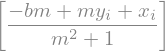

In [10]:
eq1 = dD2_collected
solutions_t = solve(eq1, t)
display(solutions_t)

### 手順4：listから解を取り出す

解は1個なので，`[0]`でlistの最初の要素を取り出します．これが直交射影点$Q(t_\perp)$の$x$座標です．

In [11]:
# 課題用穴埋めコード：listから解を取り出します．
# t_perp = solutions_t[   ]
# display(t_perp)

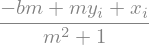

In [12]:
t_perp = solutions_t[0]
display(t_perp)

### 手順5：解を元の式へ代入する

求めた$t_\perp$を`subs`で距離平方へ代入します．出力を見てから，`factor`で人が読みやすい形に整理します．

In [13]:
# 課題用穴埋めコード：解を距離平方へ代入します．
# D2_at_perp = D2.subs({             :             })
# pprint(D2_at_perp)

# d_i_squared = factor(             )
# display(d_i_squared)

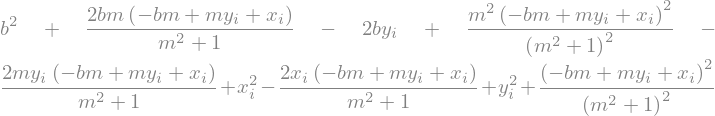

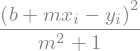

In [14]:
D2_at_perp = D2.subs({t: t_perp})
display(D2_at_perp)

d_i_squared = factor(D2_at_perp)
display(d_i_squared)

### 手順6：縦残差を代入して関係を確認する

縦残差$r_i=y_i-(mx_i+b)$を`residual`として定義します．得られた最小距離平方と$r_i^2/(1+m^2)$との差を`simplify`し，0になることを確認します．

In [15]:
# 課題用穴埋めコード：縦残差による式との差を調べます．
# residual =
# relation_check = simplify(
#     d_i_squared -              /(1 + m**2)
# )
# display(residual)
# print('二つの式の差 =', relation_check)

In [16]:
residual = y_i - (m*x_i + b)
relation_check = simplify(
    d_i_squared - residual**2/(1 + m**2)
)
display(residual)
print('二つの式の差 =', relation_check)

二つの式の差 = 0


### 手順7：平方根を取り，答えをまとめる

$d_i$は距離なので非負です．したがって，$r_i$の符号にかかわらず分子は$|r_i|$となります．2階微分も表示し，$t_\perp$が最大点ではなく最小点であることを確認します．

In [17]:
# 課題用穴埋めコード：平方根を取り，2階微分も確認します．
# d_i_in_r = Abs(             ) / sqrt(             )
# second_derivative = diff(D2, t,             )

# display(Eq(d_i, d_i_in_r))
# print('2階微分 =', second_derivative)
# print('2階微分は常に正か =', second_derivative.is_positive)

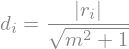

2階微分 = 2*(m**2 + 1)
2階微分は常に正か = True


In [18]:
d_i_in_r = Abs(r_i) / sqrt(1 + m**2)
second_derivative = diff(D2, t, 2)

display(Eq(d_i, d_i_in_r))
print('2階微分 =', second_derivative)
print('2階微分は常に正か =', second_derivative.is_positive)

以上より，空欄は
$$
\fbox{ア}=1，\qquad
\fbox{イ}=b，\qquad
\fbox{ウ}=1，\qquad
\fbox{エ}=1，\qquad
\fbox{オ}=r_i，\qquad
\fbox{カ}=m^2
$$
です．したがって，
$$
d_i^2=\frac{r_i^2}{1+m^2}，\qquad
d_i=\frac{|r_i|}{\sqrt{1+m^2}}
$$
となります．

## 2-1　全データ点への一般化

各点について二乗すると，
$$
d_i^2=\frac{r_i^2}{1+m^2}
$$
です．傾き$m$は全データ点で共通なので，総和を取ると，
$$
\sum_{i=1}^n d_i^2
=\frac{1}{1+m^2}\sum_{i=1}^n r_i^2
=\frac{\sum_{i=1}^n\{y_i-(mx_i+b)\}^2}{1+m^2}
$$
となります．したがって，固定した1本の直線について，直交距離平方和は縦残差平方和を$1+m^2$で割れば求められます．

# 3　全データ点での確認

次の6点と直線$y=\frac54x$について，縦残差平方和と直交距離平方和をNumPyで計算します．数値を4桁程度で表示し，
$$
\text{直交距離平方和}
=\frac{\text{縦残差平方和}}{1+m^2}
$$
となることを目視で確認してください．

## 3-1　NumPy配列を関数に渡すときの考え方

NumPy配列を`def`で定義した関数へ渡したとき，`def`そのものが自動的にPythonのloopを回すわけではありません．関数内の演算をNumPyの**配列演算**で記述しているため，ベクトル全体をまとめて処理できます．

例えば，

```python
import numpy as np

def sum_of_squares(v):
    return np.sum(v**2)
```

に`v = np.array([1, 2, 3])`を渡すと，`v**2`は各要素に二乗を適用して`[1, 4, 9]`を作り，`np.sum`はその全要素を足して`14`という1個の値にまとめます．このように複数の値を1個にまとめる演算を**reduction**と呼びます．

このノートブックの式は，次の順に処理されます．

| NumPyの式 | 処理 |
|:--|:--|
| `m*x` | スカラー`m`を`x`の各要素に掛ける |
| `y - (m*x + b)` | 同じ位置の要素どうしで縦残差を求める |
| `vertical_residuals**2` | 各縦残差を二乗する |
| `np.sum(vertical_residuals**2)` | 二乗した値をすべて足して1個の値にまとめる |

スカラー`m`や`b`を配列の各要素へ適用する仕組みを**broadcasting**と呼びます．この書き方ではPythonの`for`文は現れませんが，loopが消えたわけではありません．NumPyの内部で，主にコンパイル済みの高速な処理としてloopが実行されます．配列全体を対象としてこのように記述する方法を**vectorization**と呼びます．

NumPy配列の和には，Python組み込みの`sum(v)`より，`np.sum(v)`または`v.sum()`を使うのが自然です．2次元配列では，`axis`によって集約する方向を指定できます．

```python
A.sum()         # 全要素の和
A.sum(axis=0)   # 列ごとの和
A.sum(axis=1)   # 行ごとの和
```

なお，関数内にNumPyの配列演算を書けば何でも自動的にベクトル対応するわけではありません．例えば，配列`v`に対して通常の`if v > 0:`を書くと，複数の真偽値のどれを使うか決められないためエラーになります．配列を扱う関数では，使用する演算が配列に対応しているかを確認する必要があります．

In [19]:
# 課題用穴埋めコード：全データ点で関係を確認します．
import numpy as np

x = np.array([3, -4, 7, 1, -4, -3], dtype=float)
y = np.array([7, -6, 8, -1, -1, -7], dtype=float)
m = 5/4
b = 0.0

# vertical_residuals =
# orthogonal_distances =
# vertical_sse = np.sum(             )
# orthogonal_sse = np.sum(             )

# print('縦残差 =', vertical_residuals.round(4))
# print('直交距離 =', orthogonal_distances.round(4))
# print('縦残差平方和 =', round(vertical_sse, 4))
# print('直交距離平方和 =', round(orthogonal_sse, 4))
# print('縦残差平方和/(1+m**2) =',
#       round(vertical_sse/(1 + m**2), 4))

In [20]:
import numpy as np

x = np.array([3, -4, 7, 1, -4, -3], dtype=float)
y = np.array([7, -6, 8, -1, -1, -7], dtype=float)
m = 5/4
b = 0.0

vertical_residuals = y - (m*x + b)
orthogonal_distances = (
    np.abs(vertical_residuals) / np.sqrt(1 + m**2)
)
vertical_sse = np.sum(vertical_residuals**2)
orthogonal_sse = np.sum(orthogonal_distances**2)

print('縦残差 =', vertical_residuals.round(4))
print('直交距離 =', orthogonal_distances.round(4))
print('縦残差平方和 =', round(vertical_sse, 4))
print('直交距離平方和 =', round(orthogonal_sse, 4))
print('縦残差平方和/(1+m**2) =',
      round(vertical_sse/(1 + m**2), 4))

縦残差 = [ 3.25 -1.   -0.75 -2.25  4.   -3.25]
直交距離 = [2.0303 0.6247 0.4685 1.4056 2.4988 2.0303]
縦残差平方和 = 43.75
直交距離平方和 = 17.0732
縦残差平方和/(1+m**2) = 17.0732


# まとめ

直線$y=mx+b$に対して，縦残差$r_i$と直交距離$d_i$の間には
$$
r_i=y_i-(mx_i+b)，\qquad
d_i=\frac{|r_i|}{\sqrt{1+m^2}}
$$
という関係があります．この公式をそのまま暗記するのではなく，直線上の点$Q(t)$までの距離平方を作り，微分し，方程式を解き，得られた解を元の式へ代入することで，一つ一つの操作が公式へつながることを確認しました．

このように，一見「どうして？」と思う公式も，一つ一つの操作へ分解して理解することで，孤立した式ではなく，まとまった知識として頭に残すことが可能になります．このとき，センター試験風の穴埋め問題として導出の手順を区切り，順番に空欄を埋めていく方法は，複雑な問題を小さな確認可能な段階へ分ける練習になります．これは，研究者が未知の問題を考えるときにもよく使う手です．

発展課題：ではQRで求めた直線では，斬さ2乗和が直行距離の2乗よりも小さくなる理屈を考えてください．まずは，本当に「この設問が成り立つか」から確認してね．西谷の誤解かも．．．